# Decoding Current Motor Velocity with a Mixture Density Network

This notebook compares a deterministic decoder with a Mixture Density Network (MDN) for decoding **current** hand velocity from motor cortical activity. Both models receive the same sliding-window PMd/M1 spike features and predict the same two-dimensional target `(vx, vy)`.

It includes:
- Sliding-window neural feature construction (PMd/M1 spike counts)
- Deterministic baseline decoder: two scalar outputs, `vx` and `vy`
- Mixture Density Network decoder: a distribution over two-dimensional velocity
- Deterministic comparison metrics: RMSE, MAE, R?
- Probabilistic metrics: NLL, calibration, and prediction-interval coverage

The `horizon_bins` parameter can later be increased to study future-velocity prediction. With 20-ms bins, `horizon_bins=0` predicts current velocity, while `horizon_bins=2` predicts velocity 40 ms later.


In [2]:
import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torch.distributions import MultivariateNormal

torch.manual_seed(7)
np.random.seed(7)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cuda')

## 1) Data preparation helpers

Use `prepare_mc_maze_arrays` with MC_Maze arrays after loading from NLB. The helper expects neural bins and velocities already aligned in time.

In [3]:
def prepare_mc_maze_arrays(spikes_m1: np.ndarray, spikes_pmd: np.ndarray, velocity: np.ndarray):
    """
    Combine M1 and PMd binned spikes into one neural array.

    Parameters
    ----------
    spikes_m1 : [T, N_m1]
    spikes_pmd : [T, N_pmd]
    velocity : [T, 2] (vx, vy)
    """
    if not (len(spikes_m1) == len(spikes_pmd) == len(velocity)):
        raise ValueError("M1 spikes, PMd spikes, and velocity must share the same time dimension.")
    neural = np.concatenate([spikes_m1, spikes_pmd], axis=1).astype(np.float32)
    velocity = velocity.astype(np.float32)
    return neural, velocity


def build_windowed_features(neural: np.ndarray, velocity: np.ndarray, window_bins: int = 5, horizon_bins: int = 2):
    """
    Build temporally inclusive features and velocity targets.

    For each anchor time t, uses neural bins [t-window_bins+1, ..., t]
    and predicts velocity at t + horizon_bins. Use horizon_bins=0 for current velocity.
    """
    if window_bins < 1 or horizon_bins < 0:
        raise ValueError("window_bins must be positive and horizon_bins must be non-negative.")

    T, n_neurons = neural.shape
    last_anchor = T - horizon_bins - 1
    first_anchor = window_bins - 1
    n_samples = last_anchor - first_anchor + 1
    if n_samples <= 0:
        raise ValueError("Not enough time bins for selected window/horizon.")

    X = np.zeros((n_samples, window_bins * n_neurons), dtype=np.float32)
    y = np.zeros((n_samples, 2), dtype=np.float32)

    out_idx = 0
    for t in range(first_anchor, last_anchor + 1):
        window = neural[t - window_bins + 1 : t + 1]  # [window_bins, n_neurons]
        X[out_idx] = window.reshape(-1)
        y[out_idx] = velocity[t + horizon_bins]
        out_idx += 1

    return X, y


def split_train_val_test(X: np.ndarray, y: np.ndarray, train_frac=0.7, val_frac=0.15):
    n = len(X)
    n_train = int(n * train_frac)
    n_val = int(n * val_frac)

    X_train, y_train = X[:n_train], y[:n_train]
    X_val, y_val = X[n_train:n_train + n_val], y[n_train:n_train + n_val]
    X_test, y_test = X[n_train + n_val:], y[n_train + n_val:]
    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

## 2) Models

In [4]:
class BaselineDecoder(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 256, output_dim: int = 2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.net(x)


class MDNDecoder(nn.Module):
    def __init__(self, input_dim: int, n_components: int = 5, hidden_dim: int = 256, out_dim: int = 2):
        super().__init__()
        self.n_components = n_components
        self.out_dim = out_dim
        self.backbone = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        self.pi_head = nn.Linear(hidden_dim, n_components)
        self.mu_head = nn.Linear(hidden_dim, n_components * out_dim)
        # 2x2 lower-triangular covariance -> [l11, l21, l22]
        self.chol_head = nn.Linear(hidden_dim, n_components * 3)

    def forward(self, x):
        h = self.backbone(x)
        logits = self.pi_head(h)
        mu = self.mu_head(h).view(-1, self.n_components, self.out_dim)
        chol_raw = self.chol_head(h).view(-1, self.n_components, 3)

        L = torch.zeros(x.size(0), self.n_components, 2, 2, device=x.device)
        L[..., 0, 0] = F.softplus(chol_raw[..., 0]) + 1e-4
        L[..., 1, 0] = chol_raw[..., 1]
        L[..., 1, 1] = F.softplus(chol_raw[..., 2]) + 1e-4

        return logits, mu, L


def mdn_nll(logits, mu, L, y):
    # y: [B, 2]
    y_expanded = y.unsqueeze(1).expand_as(mu)
    mvn = MultivariateNormal(loc=mu, scale_tril=L)
    comp_log_prob = mvn.log_prob(y_expanded)  # [B, K]
    log_pi = F.log_softmax(logits, dim=-1)
    log_mix = torch.logsumexp(log_pi + comp_log_prob, dim=-1)
    return -log_mix.mean()

## 3) Training + evaluation utilities

In [5]:
def make_loader(X, y, batch_size=256, shuffle=False):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_baseline(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_state, best_val = None, float("inf")
    history = {"train_loss": [], "val_loss": []}

    for _ in range(epochs):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = F.mse_loss(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_losses.append(F.mse_loss(model(xb), yb).item())
        train = float(np.mean(train_losses))
        val = float(np.mean(val_losses))
        history["train_loss"].append(train)
        history["val_loss"].append(val)
        if val < best_val:
            best_val = val
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, history


def train_mdn(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_state, best_val = None, float("inf")
    history = {"train_loss": [], "val_loss": []}

    for _ in range(epochs):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits, mu, L = model(xb)
            loss = mdn_nll(logits, mu, L, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits, mu, L = model(xb)
                val_losses.append(mdn_nll(logits, mu, L, yb).item())
        train = float(np.mean(train_losses))
        val = float(np.mean(val_losses))
        history["train_loss"].append(train)
        history["val_loss"].append(val)
        if val < best_val:
            best_val = val
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, history


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true, axis=0, keepdims=True)) ** 2)
    return float(1.0 - ss_res / (ss_tot + 1e-8))


def mdn_predictive_mean(logits, mu):
    pi = torch.softmax(logits, dim=-1).unsqueeze(-1)  # [B, K, 1]
    return (pi * mu).sum(dim=1)  # [B, 2]


def mdn_batch_nll(logits, mu, L, y):
    y_expanded = y.unsqueeze(1).expand_as(mu)
    mvn = MultivariateNormal(loc=mu, scale_tril=L)
    comp_log_prob = mvn.log_prob(y_expanded)
    log_pi = F.log_softmax(logits, dim=-1)
    return -(torch.logsumexp(log_pi + comp_log_prob, dim=-1))


def interval_coverage(y_true, lower, upper):
    inside = ((y_true >= lower) & (y_true <= upper)).all(axis=1)
    return float(np.mean(inside))


def mdn_sample(logits, mu, L, n_samples=200):
    """Draw Monte Carlo samples from mixture for each batch element."""
    B, K, _ = mu.shape
    pi = torch.softmax(logits, dim=-1)
    cat = torch.distributions.Categorical(pi)
    comp_idx = cat.sample((n_samples,))  # [S, B]

    samples = torch.zeros(n_samples, B, 2, device=mu.device)
    for b in range(B):
        means_b = mu[b]          # [K, 2]
        L_b = L[b]               # [K, 2, 2]
        idx_b = comp_idx[:, b]   # [S]
        z = torch.randn(n_samples, 2, device=mu.device)
        L_sel = L_b[idx_b]       # [S, 2, 2]
        m_sel = means_b[idx_b]   # [S, 2]
        samples[:, b] = m_sel + torch.einsum("sij,sj->si", L_sel, z)
    return samples

## 4) Exploring the data

### Setup

First, let's make the necessary imports and load the dataset.

In [6]:
from nlb_tools.nwb_interface import NWBDataset

## Load dataset
dataset = NWBDataset("sub-Jenkins/", "*train", split_heldout=False)

### Continuous data

The continuous data provided with the MC_Maze datasets includes:
* `cursor_pos` - x and y position of the cursor controlled by the monkey
* `eye_pos` - x and y position of the monkey's point of gaze on the screen, in mm
* `hand_pos` - x and y position of the monkey's hand, in mm
* `hand_vel` - x and y velocities of the monkey's hand, in mm/s, computed offline using `np.gradient`
* `spikes` - spike times binned at 1 ms

In [7]:
## View 'dataset.data'
dataset.data

signal_type             cursor_pos            eye_pos           hand_pos  \
channel                          x          y       x      y           x   
clock_time                                                                 
0 days 00:00:00          -0.900000  -5.700000     7.2    2.0   -0.714908   
0 days 00:00:00.001000   -0.907457  -5.687027     7.2    2.1   -0.717532   
0 days 00:00:00.002000   -0.912768  -5.672115     7.6    1.2   -0.720323   
0 days 00:00:00.003000   -0.914050  -5.653433     7.4    1.4   -0.723278   
0 days 00:00:00.004000   -0.909980  -5.629617     7.4    3.6   -0.726362   
...                            ...        ...     ...    ...         ...   
0 days 01:55:52.296000 -114.378901 -79.712313   -95.0 -117.5 -114.334012   
0 days 01:55:52.297000 -114.366164 -79.728485   -94.9 -117.4 -114.333252   
0 days 01:55:52.298000 -114.365911 -79.749577   -94.6 -117.7 -114.332816   
0 days 01:55:52.299000 -114.378419 -79.774473   -94.8 -117.7 -114.332814   
0 days 01:55:52.300000 -114.400000 -79.800000   -97.8 -118.2 -114.333242   

signal_type                         hand_vel            spikes       ...       \
channel                          y         x          y   1011 1021  ... 2861   
clock_time                                                           ...        
0 days 00:00:00         -40.526123 -2.624567  29.977111    0.0  0.0  ...  0.0   
0 days 00:00:00.001000  -40.496146 -2.707321  30.577662    0.0  0.0  ...  0.0   
0 days 00:00:00.002000  -40.464968 -2.872729  31.744164    0.0  0.0  ...  0.0   
0 days 00:00:00.003000  -40.432658 -3.019660  32.847931    0.0  0.0  ...  0.0   
0 days 00:00:00.004000  -40.399272 -3.059403  33.895227    0.0  0.0  ...  0.0   
...                            ...       ...        ...    ...  ...  ...  ...   
0 days 01:55:52.296000 -114.809976  0.905895  -0.883716    0.0  0.0  ...  0.0   
0 days 01:55:52.297000 -114.810622  0.598148  -0.420075    0.0  0.0  ...  0.0   
0 days 01:55:52.298000 -114.810816  0.218816   0.012961    0.0  0.0  ...  0.0   
0 days 01:55:52.299000 -114.810596 -0.212940   0.393580    0.0  0.0  ...  0.0   
0 days 01:55:52.300000 -114.810029 -0.427820   0.566803    0.0  0.0  ...  0.0   

signal_type                                                          
channel                2862 2871 2881 2882 2911 2931 2941 2951 2961  
clock_time                                                           
0 days 00:00:00         0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 00:00:00.001000  0.0  0.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  
0 days 00:00:00.002000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 00:00:00.003000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 00:00:00.004000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
...                     ...  ...  ...  ...  ...  ...  ...  ...  ...  
0 days 01:55:52.296000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 01:55:52.297000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 01:55:52.298000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 01:55:52.299000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  
0 days 01:55:52.300000  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  

[6952301 rows x 190 columns]

In [8]:
from pynwb import NWBHDF5IO

io = NWBHDF5IO(
    "sub-Jenkins/sub-Jenkins_ses-full_desc-train_behavior+ecephys.nwb",
    "r",
)
nwb = io.read()

print(nwb.electrodes.to_dataframe()[["location", "group_name"]])
io.close()

    location           group_name
id                               
1        PMd  electrode_group_PMd
2        PMd  electrode_group_PMd
3        PMd  electrode_group_PMd
4        PMd  electrode_group_PMd
5        PMd  electrode_group_PMd
..       ...                  ...
188       M1   electrode_group_M1
189       M1   electrode_group_M1
190       M1   electrode_group_M1
191       M1   electrode_group_M1
192       M1   electrode_group_M1

[192 rows x 2 columns]


## 5) Prepare data and train both decoders

The training and validation/test partitions below are temporal partitions of the labeled training recording. Both models use exactly the same inputs and current-velocity targets, so their deterministic predictions can be compared fairly.



In [9]:
# Rebin from 1 ms to 20 ms; horizon_bins=0 decodes current velocity.
dataset.resample(20)
data = dataset.data

spike_data = data["spikes"]

pmd_channels = [c for c in spike_data.columns if 1000 <= c < 2000]
m1_channels = [c for c in spike_data.columns if 2000 <= c < 3000]

spikes_m1 = spike_data[m1_channels].to_numpy(dtype=np.float32)
spikes_pmd = spike_data[pmd_channels].to_numpy(dtype=np.float32)
velocity = data["hand_vel"][["x", "y"]].to_numpy(dtype=np.float32)

# Remove rows with missing values.
valid = (
    np.isfinite(spikes_m1).all(axis=1)
    & np.isfinite(spikes_pmd).all(axis=1)
    & np.isfinite(velocity).all(axis=1)
)

spikes_m1 = spikes_m1[valid]
spikes_pmd = spikes_pmd[valid]
velocity = velocity[valid]

neural, vel = prepare_mc_maze_arrays(spikes_m1, spikes_pmd, velocity)
X, y = build_windowed_features(
    neural,
    vel,
    window_bins=5,
    horizon_bins=0,
)

(train_X, train_y), (val_X, val_y), (test_X, test_y) = split_train_val_test(X, y)

train_loader = make_loader(train_X, train_y, batch_size=256, shuffle=True)
val_loader = make_loader(val_X, val_y, batch_size=512, shuffle=False)
test_loader = make_loader(test_X, test_y, batch_size=512, shuffle=False)

In [10]:

# Train baseline model
baseline, baseline_history = train_baseline(
    BaselineDecoder(train_X.shape[1]),
    train_loader,
    val_loader,
    epochs=12,
)

In [11]:

# Train MDN model
mdn, mdn_history = train_mdn(
    MDNDecoder(train_X.shape[1], n_components=1, hidden_dim=64),
    train_loader,
    val_loader,
    epochs=12,
)

## 5) Learning curves

The baseline and MDN optimize different losses, so they are plotted in separate panels. If training and validation losses both remain high, the model may be underfitting or inadequately optimized. If training improves while validation worsens, the model may be overfitting. The best-validation checkpoint is restored before final test evaluation.


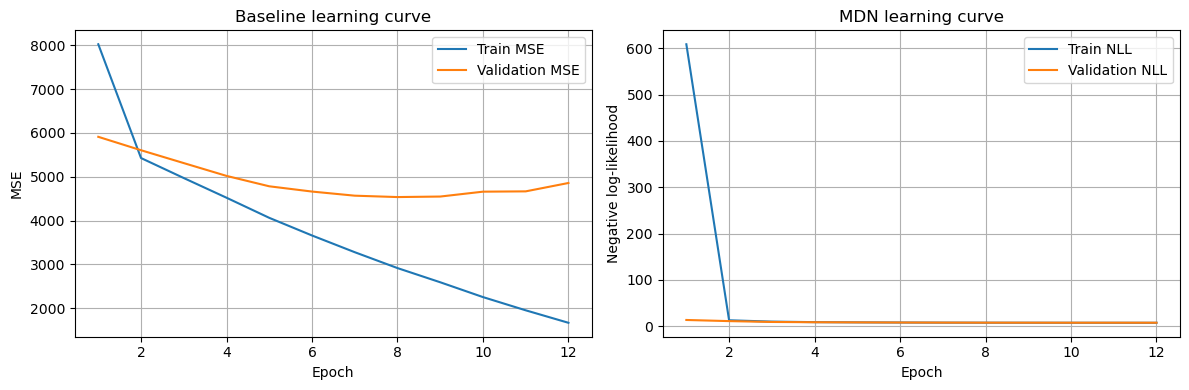

Train mean/std: [ 6.1506567 -0.6744917] [140.66881 126.27333]
Val mean/std: [5.2869134  0.36605668] [139.5949  129.55411]
Test mean/std: [ 5.145706  -2.1937695] [138.57422 128.14513]
Baseline validation MSE: 4857.065268695945
MDN final train NLL: 7.560837148982573
MDN final validation NLL: 7.704053350014262


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_baseline = np.arange(1, len(baseline_history["train_loss"]) + 1)
epochs_mdn = np.arange(1, len(mdn_history["train_loss"]) + 1)

axes[0].plot(epochs_baseline, baseline_history["train_loss"], label="Train MSE")
axes[0].plot(epochs_baseline, baseline_history["val_loss"], label="Validation MSE")
axes[0].set_title("Baseline learning curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_mdn, mdn_history["train_loss"], label="Train NLL")
axes[1].plot(epochs_mdn, mdn_history["val_loss"], label="Validation NLL")
axes[1].set_title("MDN learning curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Negative log-likelihood")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Train mean/std:", train_y.mean(axis=0), train_y.std(axis=0))
print("Val mean/std:", val_y.mean(axis=0), val_y.std(axis=0))
print("Test mean/std:", test_y.mean(axis=0), test_y.std(axis=0))

print("Baseline validation MSE:", baseline_history["val_loss"][-1])
print("MDN final train NLL:", mdn_history["train_loss"][-1])
print("MDN final validation NLL:", mdn_history["val_loss"][-1])

## 6) Evaluate point predictions and predictive uncertainty

The baseline produces a deterministic two-dimensional velocity prediction. The MDN produces a full mixture distribution; its weighted component mean is used for a point-prediction comparison, while its samples and intervals evaluate uncertainty.


In [13]:
baseline.eval()
mdn.eval()

all_y, all_baseline, all_mdn_mean, all_mdn_nll = [], [], [], []
all_q05, all_q95 = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        # baseline
        pred_b = baseline(xb)

        # mdn
        logits, mu, L = mdn(xb)
        pred_m = mdn_predictive_mean(logits, mu)
        nll_batch = mdn_batch_nll(logits, mu, L, yb)

        # sample-based prediction intervals and calibration proxy
        samples = mdn_sample(logits, mu, L, n_samples=300).cpu().numpy()  # [S, B, 2]
        q05 = np.quantile(samples, 0.05, axis=0)
        q95 = np.quantile(samples, 0.95, axis=0)

        all_y.append(yb.cpu().numpy())
        all_baseline.append(pred_b.cpu().numpy())
        all_mdn_mean.append(pred_m.cpu().numpy())
        all_mdn_nll.append(nll_batch.cpu().numpy())
        all_q05.append(q05)
        all_q95.append(q95)

Y = np.concatenate(all_y)
B = np.concatenate(all_baseline)
M = np.concatenate(all_mdn_mean)
NLL = np.concatenate(all_mdn_nll)
Q05 = np.concatenate(all_q05)
Q95 = np.concatenate(all_q95)

results = {
    "baseline_rmse": rmse(Y, B),
    "baseline_mae": mae(Y, B),
    "baseline_r2": r2(Y, B),
    "mdn_rmse_from_mean": rmse(Y, M),
    "mdn_mae_from_mean": mae(Y, M),
    "mdn_r2_from_mean": r2(Y, M),
    "mdn_nll": float(np.mean(NLL)),
    "mdn_90pct_interval_coverage": interval_coverage(Y, Q05, Q95),
}

results

{'baseline_rmse': 66.35579681396484,
 'baseline_mae': 25.04625701904297,
 'baseline_r2': 0.752830929804475,
 'mdn_rmse_from_mean': 132.65504455566406,
 'mdn_mae_from_mean': 43.2015495300293,
 'mdn_r2_from_mean': 0.012165931258147356,
 'mdn_nll': 7.8464274406433105,
 'mdn_90pct_interval_coverage': 0.8531109810805539}

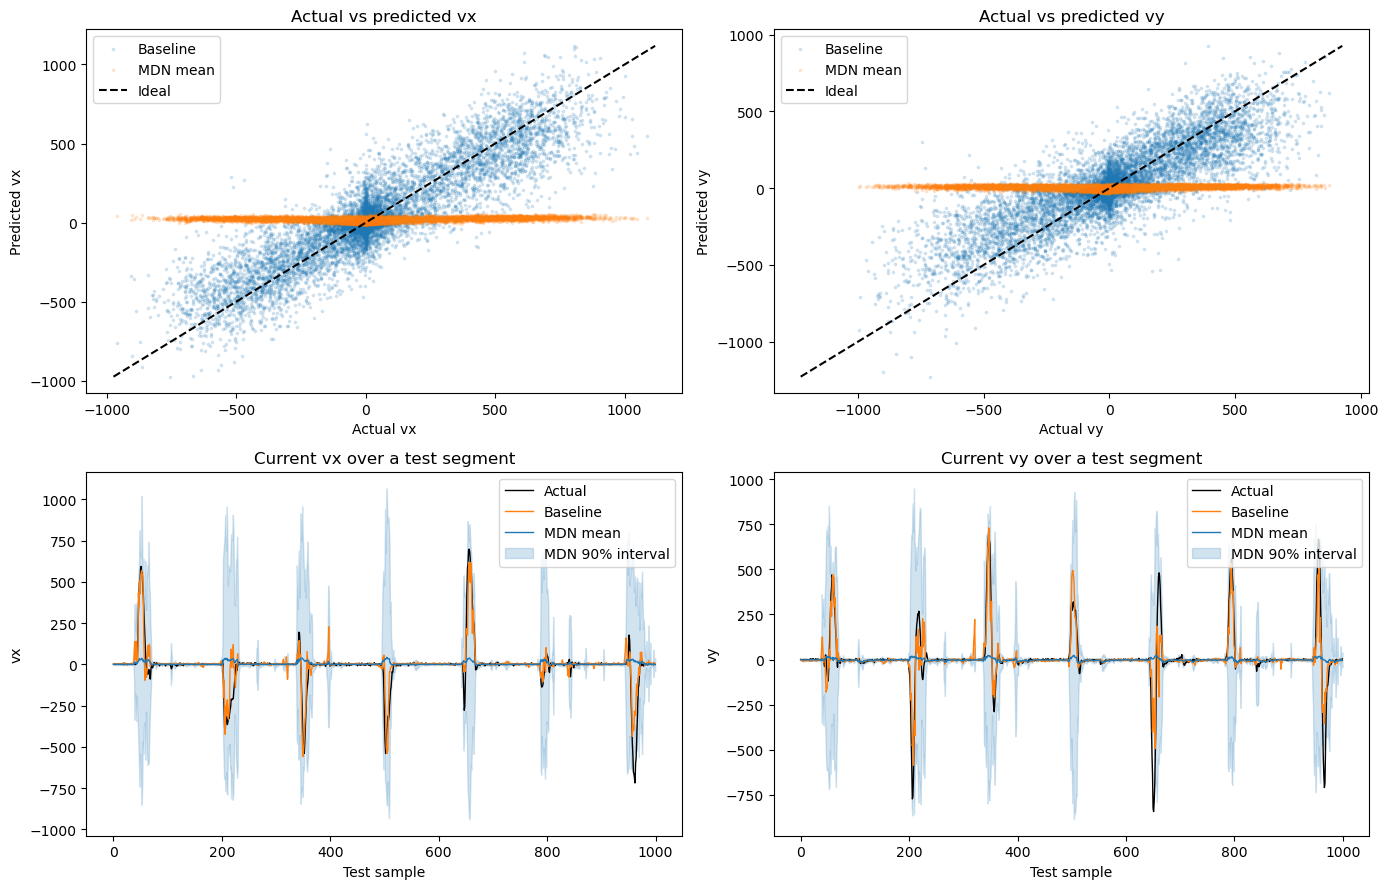

In [14]:
# Compare point predictions and show the MDN's 90% predictive interval.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, label in enumerate(["vx", "vy"]):
    axes[0, i].scatter(Y[:, i], B[:, i], s=3, alpha=0.15, label="Baseline")
    axes[0, i].scatter(Y[:, i], M[:, i], s=3, alpha=0.15, label="MDN mean")
    lo = min(Y[:, i].min(), B[:, i].min(), M[:, i].min())
    hi = max(Y[:, i].max(), B[:, i].max(), M[:, i].max())
    axes[0, i].plot([lo, hi], [lo, hi], "k--", label="Ideal")
    axes[0, i].set_xlabel(f"Actual {label}")
    axes[0, i].set_ylabel(f"Predicted {label}")
    axes[0, i].set_title(f"Actual vs predicted {label}")
    axes[0, i].legend()

n_plot = min(1000, len(Y))
time = np.arange(n_plot)
for i, label in enumerate(["vx", "vy"]):
    axes[1, i].plot(time, Y[:n_plot, i], color="black", linewidth=1, label="Actual")
    axes[1, i].plot(time, B[:n_plot, i], color="tab:orange", linewidth=1, label="Baseline")
    axes[1, i].plot(time, M[:n_plot, i], color="tab:blue", linewidth=1, label="MDN mean")
    axes[1, i].fill_between(
        time,
        Q05[:n_plot, i],
        Q95[:n_plot, i],
        color="tab:blue",
        alpha=0.2,
        label="MDN 90% interval",
    )
    axes[1, i].set_xlabel("Test sample")
    axes[1, i].set_ylabel(label)
    axes[1, i].set_title(f"Current {label} over a test segment")
    axes[1, i].legend()

plt.tight_layout()
plt.show()


## 7) Calibration summary

Calibration checks whether the MDN's uncertainty intervals have the coverage they claim. For example, a nominal 90% interval should contain the true velocity about 90% of the time. This notebook reports joint coverage, meaning both `vx` and `vy` must be inside the interval.


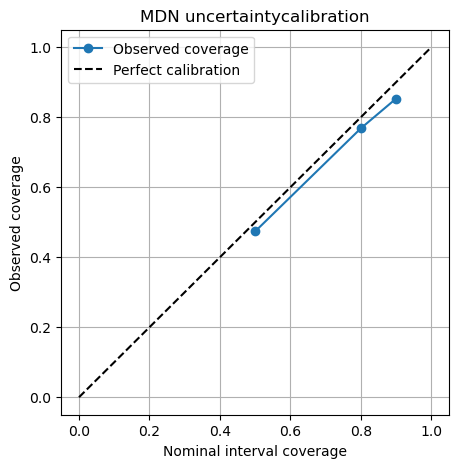

In [15]:
def calibration_table(y_true, samples, levels=(0.5, 0.8, 0.9)):
    rows = []
    for level in levels:
        lo = (1 - level) / 2
        hi = 1 - lo
        q_lo = np.quantile(samples, lo, axis=0)
        q_hi = np.quantile(samples, hi, axis=0)
        coverage = interval_coverage(y_true, q_lo, q_hi)
        rows.append((level, coverage))
    return rows

# Recompute sample set over the test partition once for calibration table
all_samples = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(DEVICE)
        logits, mu, L = mdn(xb)
        all_samples.append(mdn_sample(logits, mu, L, n_samples=300).cpu().numpy())

samples_test = np.concatenate(all_samples, axis=1)  # [S, N, 2]
calibration = calibration_table(Y, samples_test, levels=(0.5, 0.8, 0.9))
calibration

nominal = [level for level, _ in calibration]
observed = [coverage for _, coverage in calibration]

plt.figure(figsize=(5, 5))
plt.plot(nominal, observed, "o-", label="Observed coverage")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Nominal interval coverage")
plt.ylabel("Observed coverage")
plt.title("MDN uncertaintycalibration")
plt.legend()
plt.grid(True)
plt.show()